# Sudoku con Reinforcement Learning

Un agente de Reinforcement Learning que aprende a resolver puzzles de Sudoku 4x4 usando Q-Learning.

---

## ¿Por qué Sudoku con RL?

Sudoku es un problema interesante para RL porque:

- **El espacio de estados es enorme**: incluso en un Sudoku 4x4, hay miles de configuraciones posibles.
- **Las acciones tienen consecuencias a largo plazo**: poner un número incorrecto en una celda puede hacer imposible completar el puzzle más adelante.
- **La recompensa es retardada**: solo al final sabemos si la solución es correcta.
- **Hay restricciones duras**: filas, columnas y subcuadrículas deben contener números únicos.

### ¿Por qué 4x4 y no 9x9?

Un Sudoku 9x9 tiene un espacio de estados astronómicamente grande para Q-Learning tabular. Usamos **4x4** (con números 1-4) para que el agente pueda aprender en un tiempo razonable y podamos visualizar todo el proceso.

| Aspecto | Sudoku 4x4 | Sudoku 9x9 |
|---|---|---|
| Números | 1-4 | 1-9 |
| Celdas | 16 | 81 |
| Subcuadrículas | 4 (2x2) | 9 (3x3) |
| Espacio de estados | ~Manejable | ~$6.7 \times 10^{21}$ |
| Q-Learning tabular | ✅ Posible | ❌ Necesita Deep RL |

### Formulación como MDP

- **Estado**: configuración actual del tablero (qué números hay en cada celda)
- **Acción**: colocar un número (1-4) en una celda vacía específica
- **Recompensa**:
  - +10 por colocar un número válido (no viola restricciones)
  - -10 por colocar un número inválido (viola fila, columna o subcuadrante)
  - +100 por completar el puzzle correctamente
  - -1 por cada paso (incentiva soluciones rápidas)
- **Episodio termina**: cuando el tablero está lleno o se alcanza un límite de pasos

---

## El entorno: Sudoku 4x4

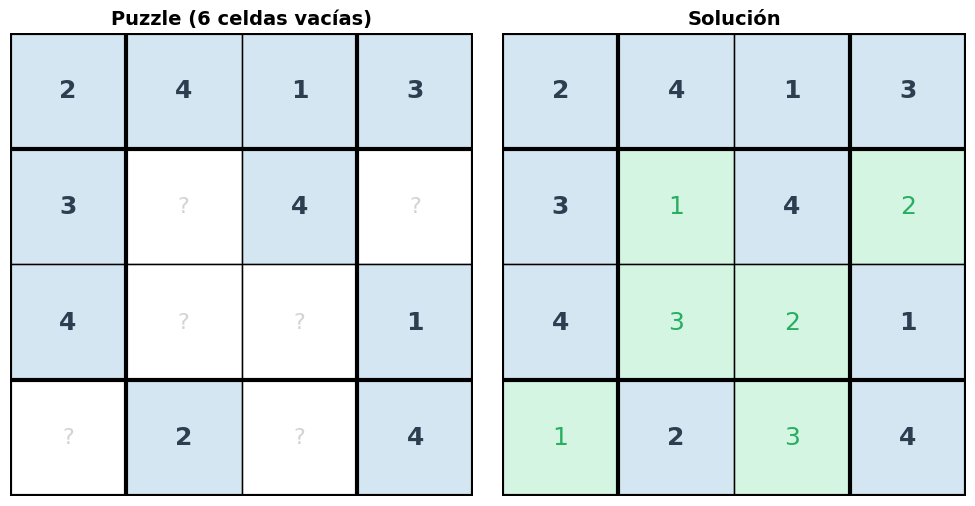

Tablero del puzzle:
[[2 4 1 3]
 [3 0 4 0]
 [4 0 0 1]
 [0 2 0 4]]

Celdas vacías: [(1, 1), (1, 3), (2, 1), (2, 2), (3, 0), (3, 2)]
Celdas fijas: {(0, 1), (1, 2), (0, 0), (3, 1), (0, 3), (2, 0), (2, 3), (0, 2), (3, 3), (1, 0)}

Probando poner 1 en (1,1) (correcto):
  Recompensa: 5, Info: {'valido': True, 'completo': False, 'correcto': np.True_}


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from copy import deepcopy


class Sudoku4x4:
    """
    Entorno de Sudoku 4x4 para Reinforcement Learning.

    El tablero usa números 1-4. Las subcuadrículas son de 2x2.
    Las celdas vacías se representan con 0.

    Parámetros
    ----------
    n_vacias : int
        Número de celdas vacías en el puzzle (dificultad).
    """

    def __init__(self, n_vacias=6):
        self.size = 4
        self.box_size = 2
        self.n_vacias = n_vacias
        self.tablero = None
        self.solucion = None
        self.celdas_fijas = None  # Celdas que vienen dadas (no se pueden cambiar)
        self.celdas_vacias_iniciales = None

    def _generar_solucion(self):
        """Genera una solución válida de Sudoku 4x4 usando backtracking."""
        tablero = np.zeros((4, 4), dtype=int)

        def es_valido(tab, fila, col, num):
            # Verificar fila
            if num in tab[fila]:
                return False
            # Verificar columna
            if num in tab[:, col]:
                return False
            # Verificar subcuadrante 2x2
            sf, sc = (fila // 2) * 2, (col // 2) * 2
            if num in tab[sf:sf+2, sc:sc+2]:
                return False
            return True

        def resolver(tab):
            for i in range(4):
                for j in range(4):
                    if tab[i, j] == 0:
                        nums = list(range(1, 5))
                        np.random.shuffle(nums)
                        for num in nums:
                            if es_valido(tab, i, j, num):
                                tab[i, j] = num
                                if resolver(tab):
                                    return True
                                tab[i, j] = 0
                        return False
            return True

        resolver(tablero)
        return tablero

    def reset(self):
        """
        Genera un nuevo puzzle de Sudoku.

        Retorna
        -------
        tablero : array (4, 4)
            El puzzle con celdas vacías (0).
        """
        self.solucion = self._generar_solucion()
        self.tablero = self.solucion.copy()

        # Vaciar celdas aleatorias
        todas_celdas = [(i, j) for i in range(4) for j in range(4)]
        np.random.shuffle(todas_celdas)
        vacias = todas_celdas[:self.n_vacias]

        for (i, j) in vacias:
            self.tablero[i, j] = 0

        self.celdas_fijas = set()
        for i in range(4):
            for j in range(4):
                if self.tablero[i, j] != 0:
                    self.celdas_fijas.add((i, j))

        self.celdas_vacias_iniciales = [(i, j) for i in range(4) for j in range(4)
                                         if self.tablero[i, j] == 0]

        return self.tablero.copy()

    def get_celdas_vacias(self):
        """Retorna lista de celdas vacías actuales."""
        return [(i, j) for i in range(4) for j in range(4) if self.tablero[i, j] == 0]

    def es_movimiento_valido(self, fila, col, num):
        """
        Verifica si colocar 'num' en (fila, col) es válido.
        No viola restricciones de fila, columna ni subcuadrante.
        """
        if self.tablero[fila, col] != 0:
            return False
        if (fila, col) in self.celdas_fijas:
            return False

        # Verificar fila (ignorando la celda actual)
        if num in self.tablero[fila]:
            return False
        # Verificar columna
        if num in self.tablero[:, col]:
            return False
        # Verificar subcuadrante 2x2
        sf, sc = (fila // 2) * 2, (col // 2) * 2
        if num in self.tablero[sf:sf+2, sc:sc+2]:
            return False

        return True

    def step(self, fila, col, num):
        """
        Coloca un número en el tablero.

        Retorna
        -------
        tablero : array (4, 4)
        recompensa : float
        terminado : bool
        info : dict
        """
        info = {'valido': False, 'completo': False, 'correcto': False}

        # Verificar si el movimiento es válido
        if (fila, col) in self.celdas_fijas:
            return self.tablero.copy(), -5, False, info

        if self.tablero[fila, col] != 0:
            return self.tablero.copy(), -5, False, info

        if self.es_movimiento_valido(fila, col, num):
            self.tablero[fila, col] = num
            info['valido'] = True

            # ¿Es el número correcto según la solución?
            es_correcto = (num == self.solucion[fila, col])
            info['correcto'] = es_correcto

            # Recompensa base por movimiento válido
            recompensa = 5 if es_correcto else 2

            # ¿Se completó el puzzle?
            if len(self.get_celdas_vacias()) == 0:
                info['completo'] = True
                if np.array_equal(self.tablero, self.solucion):
                    recompensa = 100  # ¡Resuelto correctamente!
                    return self.tablero.copy(), recompensa, True, info
                else:
                    recompensa = -20  # Completo pero incorrecto
                    return self.tablero.copy(), recompensa, True, info

            return self.tablero.copy(), recompensa, False, info
        else:
            # Movimiento inválido (viola restricciones)
            return self.tablero.copy(), -10, False, info

    def esta_resuelto(self):
        """Verifica si el puzzle está correctamente resuelto."""
        return np.array_equal(self.tablero, self.solucion)

    def render(self, titulo='Sudoku 4x4', ax=None, mostrar_solucion=False):
        """Visualiza el tablero de Sudoku."""
        show = False
        if ax is None:
            fig, ax = plt.subplots(figsize=(5, 5))
            show = True

        tab = self.solucion if mostrar_solucion else self.tablero

        for i in range(4):
            for j in range(4):
                # Color de fondo
                if (i, j) in self.celdas_fijas:
                    color = '#D4E6F1'  # azul claro para fijas
                elif tab[i, j] == 0:
                    color = 'white'
                else:
                    color = '#D5F5E3'  # verde claro para colocadas por el agente

                rect = plt.Rectangle((j, 3-i), 1, 1, facecolor=color,
                                    edgecolor='gray', linewidth=1)
                ax.add_patch(rect)

                if tab[i, j] != 0:
                    peso = 'bold' if (i, j) in self.celdas_fijas else 'normal'
                    clr = '#2C3E50' if (i, j) in self.celdas_fijas else '#27AE60'
                    ax.text(j + 0.5, 3-i + 0.5, str(tab[i, j]),
                           ha='center', va='center', fontsize=18,
                           fontweight=peso, color=clr)
                else:
                    ax.text(j + 0.5, 3-i + 0.5, '?',
                           ha='center', va='center', fontsize=16,
                           color='lightgray')

        # Líneas gruesas para subcuadrantes 2x2
        for k in range(3):
            lw = 3 if k % 2 == 0 else 1
            ax.plot([0, 4], [k+1, k+1], 'k-', linewidth=lw)
            ax.plot([k+1, k+1], [0, 4], 'k-', linewidth=lw)

        # Borde exterior
        for pos in [0, 4]:
            ax.plot([0, 4], [pos, pos], 'k-', linewidth=3)
            ax.plot([pos, pos], [0, 4], 'k-', linewidth=3)

        ax.set_xlim(0, 4); ax.set_ylim(0, 4)
        ax.set_aspect('equal'); ax.axis('off')
        ax.set_title(titulo, fontsize=14, fontweight='bold')

        if show:
            plt.tight_layout(); plt.show()


# --- Prueba del entorno ---
np.random.seed(42)
env = Sudoku4x4(n_vacias=6)
tablero = env.reset()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
env.render('Puzzle (6 celdas vacías)', ax=axes[0])
env.render('Solución', ax=axes[1], mostrar_solucion=True)
plt.tight_layout(); plt.show()

print('Tablero del puzzle:')
print(tablero)
print(f'\nCeldas vacías: {env.get_celdas_vacias()}')
print(f'Celdas fijas: {env.celdas_fijas}')

# Probar movimientos
vacias = env.get_celdas_vacias()
if vacias:
    f, c = vacias[0]
    num_correcto = env.solucion[f, c]
    print(f'\nProbando poner {num_correcto} en ({f},{c}) (correcto):')
    _, r, done, info = env.step(f, c, num_correcto)
    print(f'  Recompensa: {r}, Info: {info}')

---

## Agente RL para Sudoku

Para Sudoku, el espacio de estados es demasiado grande para una tabla Q tradicional. Usamos una **representación basada en features** que codifica el estado local de cada celda vacía.

In [2]:
class SudokuAgent:
    """
    Agente Q-Learning para resolver Sudoku 4x4.

    Usa una representación de estado basada en las posibilidades
    válidas de cada celda vacía, lo cual reduce enormemente
    el espacio de estados.

    Parámetros
    ----------
    alpha : float
        Tasa de aprendizaje.
    gamma : float
        Factor de descuento.
    epsilon : float
        Probabilidad de exploración inicial.
    epsilon_min : float
        Exploración mínima.
    epsilon_decay : float
        Decaimiento de epsilon.
    """

    def __init__(self, alpha=0.3, gamma=0.95, epsilon=1.0,
                 epsilon_min=0.05, epsilon_decay=0.9995):
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay

        # Q-table como diccionario: (estado_hash, accion) → Q-value
        self.Q = {}

        # Historial
        self.recompensas_historial = []
        self.resueltos_historial = []
        self.pasos_historial = []

    def _estado_hash(self, tablero):
        """Convierte el tablero en un hash para la Q-table."""
        return tuple(tablero.flatten())

    def _obtener_acciones_validas(self, env):
        """
        Obtiene todas las acciones válidas posibles.
        Una acción es (fila, col, num) donde num es válido en esa posición.
        """
        acciones = []
        for (i, j) in env.get_celdas_vacias():
            for num in range(1, 5):
                if env.es_movimiento_valido(i, j, num):
                    acciones.append((i, j, num))
        return acciones

    def _get_q(self, estado_hash, accion):
        """Obtiene Q-value, inicializando a 0 si no existe."""
        key = (estado_hash, accion)
        if key not in self.Q:
            self.Q[key] = 0.0
        return self.Q[key]

    def _set_q(self, estado_hash, accion, valor):
        """Establece Q-value."""
        self.Q[(estado_hash, accion)] = valor

    def seleccionar_accion(self, env):
        """
        Selecciona acción con epsilon-greedy.
        Solo considera acciones válidas.
        """
        acciones = self._obtener_acciones_validas(env)

        if not acciones:
            # No hay acciones válidas: elegir cualquier celda vacía con cualquier número
            vacias = env.get_celdas_vacias()
            if vacias:
                i, j = vacias[0]
                return (i, j, np.random.randint(1, 5))
            return None

        if np.random.random() < self.epsilon:
            # Exploración: acción aleatoria válida
            return acciones[np.random.randint(len(acciones))]

        # Explotación: mejor Q-value
        estado_hash = self._estado_hash(env.tablero)
        mejor_q = -np.inf
        mejor_accion = acciones[0]

        for accion in acciones:
            q = self._get_q(estado_hash, accion)
            if q > mejor_q:
                mejor_q = q
                mejor_accion = accion

        return mejor_accion

    def entrenar(self, n_episodios=5000, n_vacias=6, max_pasos=20, verbose=True):
        """
        Entrena al agente en múltiples puzzles de Sudoku.

        Parámetros
        ----------
        n_episodios : int
            Número de puzzles a intentar resolver.
        n_vacias : int
            Número de celdas vacías (dificultad).
        max_pasos : int
            Máximo de movimientos por puzzle.
        verbose : bool
            Si imprime progreso.
        """
        self.recompensas_historial = []
        self.resueltos_historial = []
        self.pasos_historial = []

        env = Sudoku4x4(n_vacias=n_vacias)
        resueltos_total = 0

        for ep in range(n_episodios):
            env.reset()
            recompensa_total = 0
            resuelto = False

            for paso in range(max_pasos):
                estado_hash = self._estado_hash(env.tablero)
                accion = self.seleccionar_accion(env)

                if accion is None:
                    break

                fila, col, num = accion
                nuevo_tablero, recompensa, terminado, info = env.step(fila, col, num)
                recompensa_total += recompensa

                # Q-Learning update
                nuevo_estado_hash = self._estado_hash(env.tablero)

                if terminado:
                    max_q_next = 0
                else:
                    acciones_siguientes = self._obtener_acciones_validas(env)
                    if acciones_siguientes:
                        max_q_next = max(self._get_q(nuevo_estado_hash, a)
                                        for a in acciones_siguientes)
                    else:
                        max_q_next = 0

                q_actual = self._get_q(estado_hash, accion)
                td_target = recompensa + self.gamma * max_q_next * (1 - terminado)
                nuevo_q = q_actual + self.alpha * (td_target - q_actual)
                self._set_q(estado_hash, accion, nuevo_q)

                if terminado:
                    if info.get('completo') and env.esta_resuelto():
                        resuelto = True
                        resueltos_total += 1
                    break

            self.recompensas_historial.append(recompensa_total)
            self.resueltos_historial.append(resuelto)
            self.pasos_historial.append(paso + 1)

            # Decaimiento de epsilon
            self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

            if verbose and (ep + 1) % (n_episodios // 10) == 0:
                ultimos = self.resueltos_historial[-500:]
                tasa = sum(ultimos) / len(ultimos) * 100
                print(f'  Episodio {ep+1:>6}/{n_episodios} | '
                      f'Resueltos (ult 500): {tasa:5.1f}% | '
                      f'ε: {self.epsilon:.4f} | '
                      f'Q-entries: {len(self.Q)}')

        if verbose:
            tasa_final = sum(self.resueltos_historial[-1000:]) / min(1000, len(self.resueltos_historial)) * 100
            print(f'\n  Entrenamiento completo!')
            print(f'  Tasa de resolución final (ult 1000): {tasa_final:.1f}%')
            print(f'  Total resueltos: {resueltos_total}/{n_episodios}')
            print(f'  Entradas en Q-table: {len(self.Q)}')

    def resolver(self, env, render_pasos=False):
        """
        Intenta resolver un puzzle usando la política aprendida (sin exploración).
        """
        pasos = []
        tablero_inicial = env.tablero.copy()

        for paso in range(20):
            acciones = self._obtener_acciones_validas(env)
            if not acciones:
                break

            # Elegir mejor acción (greedy)
            estado_hash = self._estado_hash(env.tablero)
            mejor_q = -np.inf
            mejor_accion = acciones[0]

            for accion in acciones:
                q = self._get_q(estado_hash, accion)
                if q > mejor_q:
                    mejor_q = q
                    mejor_accion = accion

            fila, col, num = mejor_accion
            _, recompensa, terminado, info = env.step(fila, col, num)
            pasos.append((fila, col, num, recompensa, info))

            if render_pasos:
                print(f'  Paso {paso+1}: Poner {num} en ({fila},{col}) → R={recompensa:+.0f} '
                      f'{"✓" if info["valido"] else "✗"}')

            if terminado:
                break

        resuelto = env.esta_resuelto()
        return resuelto, pasos

    def plot_aprendizaje(self, ventana=200):
        """Visualiza las métricas de entrenamiento."""
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))

        # Recompensa
        ax = axes[0]
        if len(self.recompensas_historial) >= ventana:
            media = np.convolve(self.recompensas_historial,
                               np.ones(ventana)/ventana, mode='valid')
            ax.plot(media, color='#3498db', linewidth=2)
        else:
            ax.plot(self.recompensas_historial, color='#3498db', linewidth=1)
        ax.set_xlabel('Episodio'); ax.set_ylabel('Recompensa')
        ax.set_title('Recompensa por episodio', fontsize=13, fontweight='bold')
        ax.grid(True, alpha=0.3)

        # Tasa de resolución
        ax = axes[1]
        if len(self.resueltos_historial) >= ventana:
            tasa = np.convolve([float(x) for x in self.resueltos_historial],
                              np.ones(ventana)/ventana, mode='valid') * 100
            ax.plot(tasa, color='#2ecc71', linewidth=2)
        ax.set_xlabel('Episodio'); ax.set_ylabel('% Resueltos')
        ax.set_title('Tasa de resolución', fontsize=13, fontweight='bold')
        ax.set_ylim(-5, 105)
        ax.grid(True, alpha=0.3)

        # Pasos por episodio
        ax = axes[2]
        if len(self.pasos_historial) >= ventana:
            media_p = np.convolve(self.pasos_historial,
                                 np.ones(ventana)/ventana, mode='valid')
            ax.plot(media_p, color='#e74c3c', linewidth=2)
        ax.set_xlabel('Episodio'); ax.set_ylabel('Pasos')
        ax.set_title('Pasos por episodio', fontsize=13, fontweight='bold')
        ax.grid(True, alpha=0.3)

        plt.suptitle('Métricas de entrenamiento del agente Sudoku',
                    fontsize=15, fontweight='bold', y=1.02)
        plt.tight_layout(); plt.show()


print('Clase SudokuAgent definida ✓')

Clase SudokuAgent definida ✓


---

## Entrenamiento

### Nivel fácil: 4 celdas vacías

=== Entrenamiento: 4 celdas vacías (fácil) ===
  Episodio   1000/10000 | Resueltos (ult 500):  96.0% | ε: 0.6065 | Q-entries: 7569
  Episodio   2000/10000 | Resueltos (ult 500):  95.6% | ε: 0.3678 | Q-entries: 15763
  Episodio   3000/10000 | Resueltos (ult 500):  98.2% | ε: 0.2230 | Q-entries: 24288
  Episodio   4000/10000 | Resueltos (ult 500):  96.0% | ε: 0.1353 | Q-entries: 32843
  Episodio   5000/10000 | Resueltos (ult 500):  96.0% | ε: 0.0820 | Q-entries: 41358
  Episodio   6000/10000 | Resueltos (ult 500):  97.0% | ε: 0.0500 | Q-entries: 49775
  Episodio   7000/10000 | Resueltos (ult 500):  96.6% | ε: 0.0500 | Q-entries: 58146
  Episodio   8000/10000 | Resueltos (ult 500):  97.2% | ε: 0.0500 | Q-entries: 66417
  Episodio   9000/10000 | Resueltos (ult 500):  96.8% | ε: 0.0500 | Q-entries: 74498
  Episodio  10000/10000 | Resueltos (ult 500):  98.0% | ε: 0.0500 | Q-entries: 82469

  Entrenamiento completo!
  Tasa de resolución final (ult 1000): 96.8%
  Total resueltos: 9653/10000
  

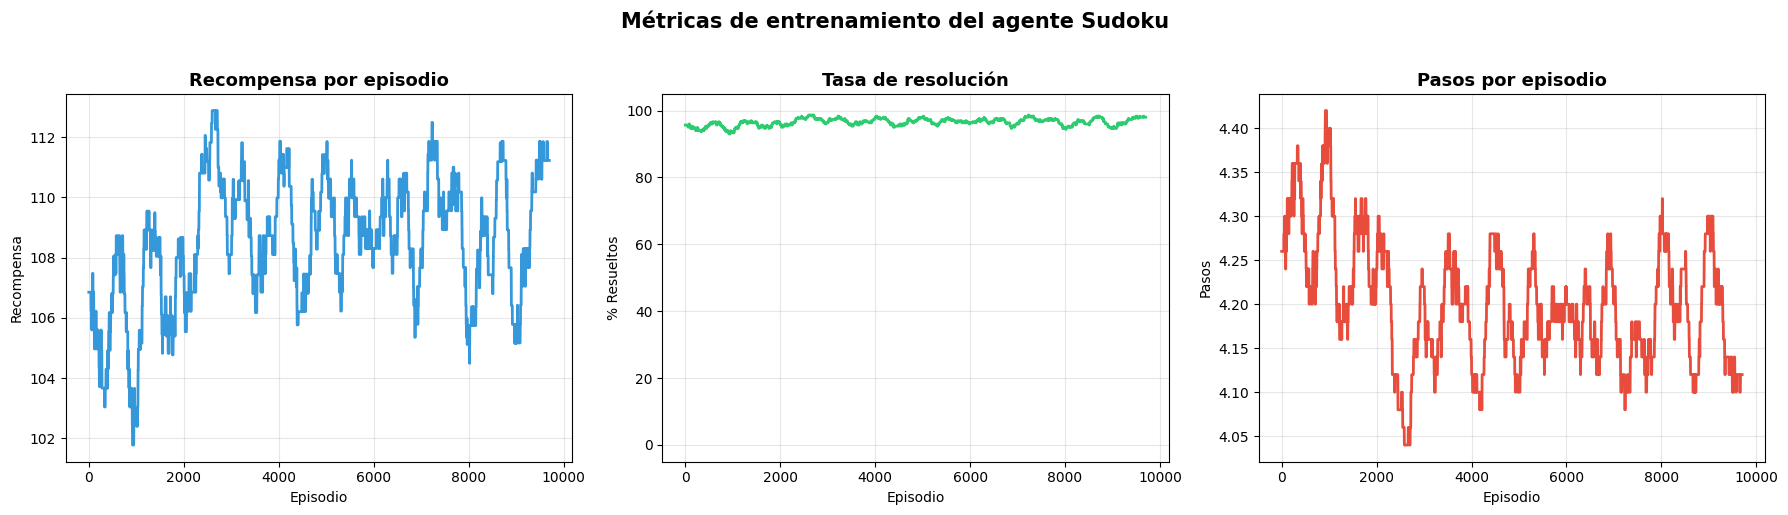

In [3]:
np.random.seed(42)

print('=== Entrenamiento: 4 celdas vacías (fácil) ===')
agente_facil = SudokuAgent(alpha=0.3, gamma=0.95, epsilon=1.0,
                            epsilon_min=0.05, epsilon_decay=0.9995)
agente_facil.entrenar(n_episodios=10000, n_vacias=4, max_pasos=10)
agente_facil.plot_aprendizaje(ventana=300)

### Nivel medio: 6 celdas vacías

=== Entrenamiento: 6 celdas vacías (medio) ===
  Episodio   2000/20000 | Resueltos (ult 500):  73.2% | ε: 0.6703 | Q-entries: 33083
  Episodio   4000/20000 | Resueltos (ult 500):  80.8% | ε: 0.4493 | Q-entries: 69210
  Episodio   6000/20000 | Resueltos (ult 500):  82.8% | ε: 0.3012 | Q-entries: 106949
  Episodio   8000/20000 | Resueltos (ult 500):  83.0% | ε: 0.2019 | Q-entries: 145081
  Episodio  10000/20000 | Resueltos (ult 500):  80.6% | ε: 0.1353 | Q-entries: 183346
  Episodio  12000/20000 | Resueltos (ult 500):  85.4% | ε: 0.0907 | Q-entries: 221720
  Episodio  14000/20000 | Resueltos (ult 500):  82.6% | ε: 0.0608 | Q-entries: 259857
  Episodio  16000/20000 | Resueltos (ult 500):  82.6% | ε: 0.0500 | Q-entries: 297458
  Episodio  18000/20000 | Resueltos (ult 500):  83.2% | ε: 0.0500 | Q-entries: 334387
  Episodio  20000/20000 | Resueltos (ult 500):  80.8% | ε: 0.0500 | Q-entries: 370733

  Entrenamiento completo!
  Tasa de resolución final (ult 1000): 81.3%
  Total resueltos: 1627

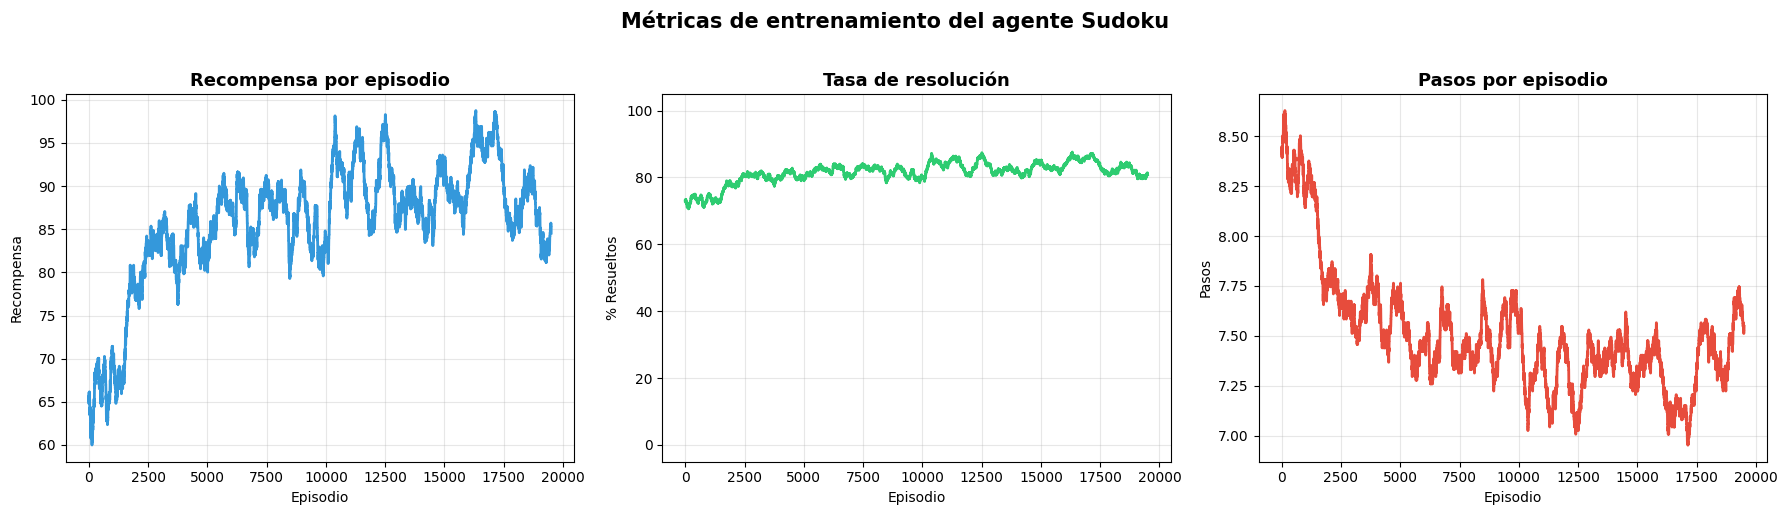

In [4]:
np.random.seed(42)

print('=== Entrenamiento: 6 celdas vacías (medio) ===')
agente_medio = SudokuAgent(alpha=0.3, gamma=0.95, epsilon=1.0,
                            epsilon_min=0.05, epsilon_decay=0.9998)
agente_medio.entrenar(n_episodios=20000, n_vacias=6, max_pasos=15)
agente_medio.plot_aprendizaje(ventana=500)

### Nivel difícil: 8 celdas vacías

=== Entrenamiento: 8 celdas vacías (difícil) ===
  Episodio   5000/50000 | Resueltos (ult 500):  44.0% | ε: 0.6065 | Q-entries: 153917
  Episodio  10000/50000 | Resueltos (ult 500):  49.0% | ε: 0.3679 | Q-entries: 325625
  Episodio  15000/50000 | Resueltos (ult 500):  55.2% | ε: 0.2231 | Q-entries: 502788
  Episodio  20000/50000 | Resueltos (ult 500):  60.2% | ε: 0.1353 | Q-entries: 682371
  Episodio  25000/50000 | Resueltos (ult 500):  60.0% | ε: 0.0821 | Q-entries: 861086
  Episodio  30000/50000 | Resueltos (ult 500):  61.2% | ε: 0.0500 | Q-entries: 1037252
  Episodio  35000/50000 | Resueltos (ult 500):  61.8% | ε: 0.0500 | Q-entries: 1209851
  Episodio  40000/50000 | Resueltos (ult 500):  59.4% | ε: 0.0500 | Q-entries: 1379268
  Episodio  45000/50000 | Resueltos (ult 500):  58.6% | ε: 0.0500 | Q-entries: 1545511
  Episodio  50000/50000 | Resueltos (ult 500):  61.0% | ε: 0.0500 | Q-entries: 1709934

  Entrenamiento completo!
  Tasa de resolución final (ult 1000): 62.1%
  Total resuel

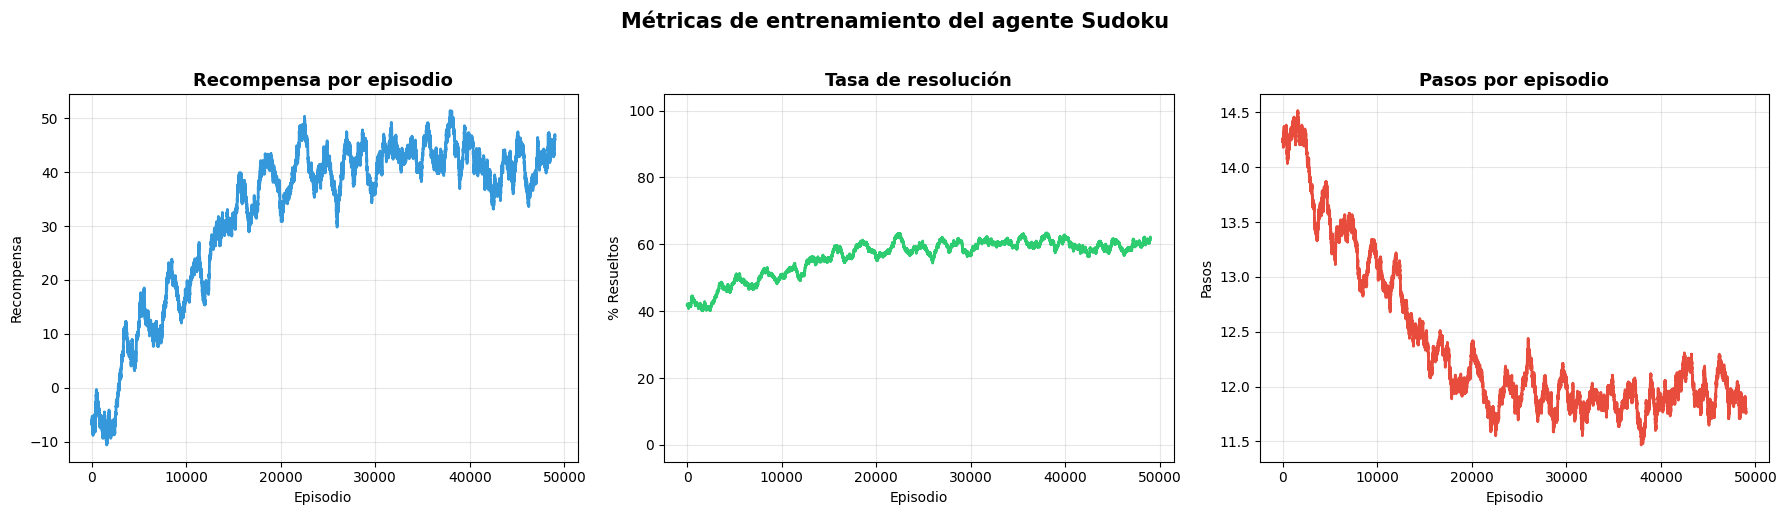

In [5]:
np.random.seed(42)

print('=== Entrenamiento: 8 celdas vacías (difícil) ===')
agente_dificil = SudokuAgent(alpha=0.2, gamma=0.95, epsilon=1.0,
                              epsilon_min=0.05, epsilon_decay=0.9999)
agente_dificil.entrenar(n_episodios=50000, n_vacias=8, max_pasos=20)
agente_dificil.plot_aprendizaje(ventana=1000)

---

## Demo: el agente resuelve puzzles

### Demo 1: Puzzle fácil paso a paso

=== DEMO: Agente resolviendo un puzzle de 4 celdas vacías ===
Celdas vacías: [(2, 1), (2, 2), (3, 0), (3, 3)]

Movimientos del agente:
  Paso 1: Poner 3 en (2,1) → R=+5 ✓
  Paso 2: Poner 1 en (2,2) → R=+5 ✓
  Paso 3: Poner 4 en (3,0) → R=+5 ✓
  Paso 4: Poner 2 en (3,3) → R=+100 ✓


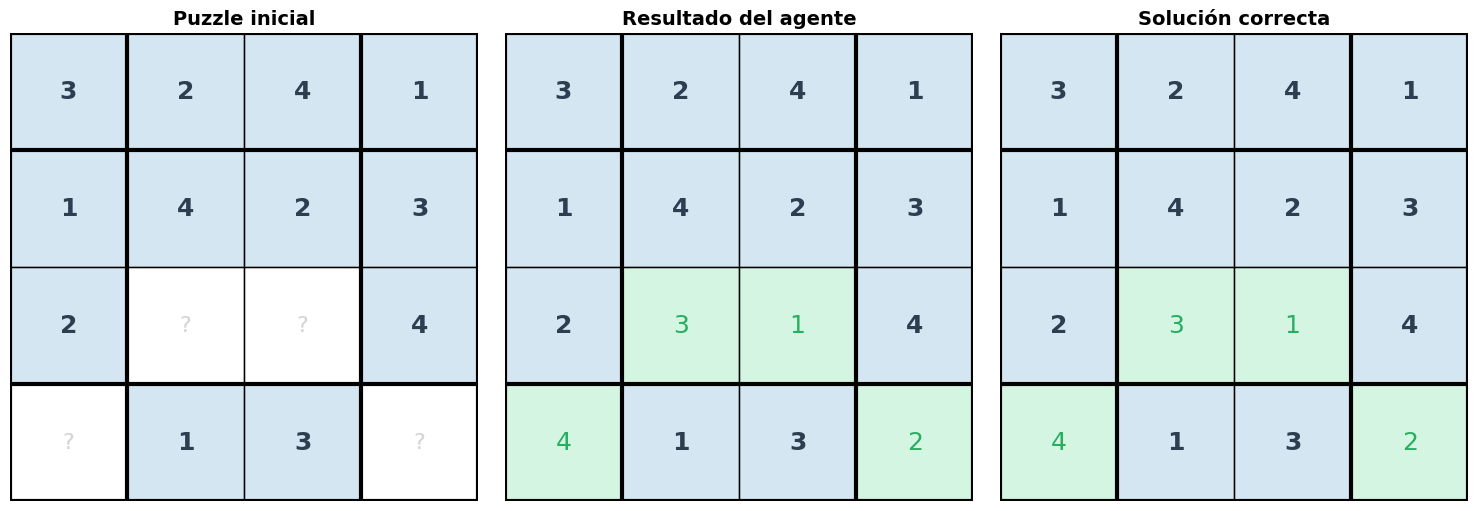


¡Puzzle RESUELTO correctamente en 4 pasos!


In [6]:
np.random.seed(100)
env_demo = Sudoku4x4(n_vacias=4)
tablero_demo = env_demo.reset()

print('=== DEMO: Agente resolviendo un puzzle de 4 celdas vacías ===')
print(f'Celdas vacías: {env_demo.get_celdas_vacias()}\n')

# Mostrar puzzle inicial
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
env_demo.render('Puzzle inicial', ax=axes[0])

# El agente resuelve
print('Movimientos del agente:')
resuelto, pasos = agente_facil.resolver(env_demo, render_pasos=True)

# Mostrar resultado
env_demo.render('Resultado del agente', ax=axes[1])
env_demo.render('Solución correcta', ax=axes[2], mostrar_solucion=True)
plt.tight_layout(); plt.show()

if resuelto:
    print(f'\n¡Puzzle RESUELTO correctamente en {len(pasos)} pasos!')
else:
    print(f'\nPuzzle NO resuelto. Pasos intentados: {len(pasos)}')

### Demo 2: Múltiples puzzles

In [7]:
# Evaluar el agente en 100 puzzles nuevos
def evaluar_agente(agente, n_puzzles=100, n_vacias=4):
    """Evalúa el agente en múltiples puzzles nuevos."""
    resueltos = 0
    pasos_totales = []

    for i in range(n_puzzles):
        env_eval = Sudoku4x4(n_vacias=n_vacias)
        env_eval.reset()
        ok, pasos = agente.resolver(env_eval)
        if ok:
            resueltos += 1
        pasos_totales.append(len(pasos))

    return resueltos, n_puzzles, np.mean(pasos_totales)


print('=== Evaluación en 100 puzzles nuevos ===')
print(f'{"Dificultad":<15} {"Resueltos":<15} {"Tasa":<10} {"Pasos prom"}')
print('-' * 55)

for nombre, agente, n_v in [('Fácil (4)', agente_facil, 4),
                              ('Medio (6)', agente_medio, 6),
                              ('Difícil (8)', agente_dificil, 8)]:
    np.random.seed(999)
    r, t, p = evaluar_agente(agente, n_puzzles=100, n_vacias=n_v)
    print(f'{nombre:<15} {r}/{t:<12} {r/t*100:>5.1f}%    {p:.1f}')

=== Evaluación en 100 puzzles nuevos ===
Dificultad      Resueltos       Tasa       Pasos prom
-------------------------------------------------------
Fácil (4)       98/100           98.0%    4.0
Medio (6)       85/100           85.0%    5.7
Difícil (8)     66/100           66.0%    7.4


### Demo 3: Visualización de resolución paso a paso

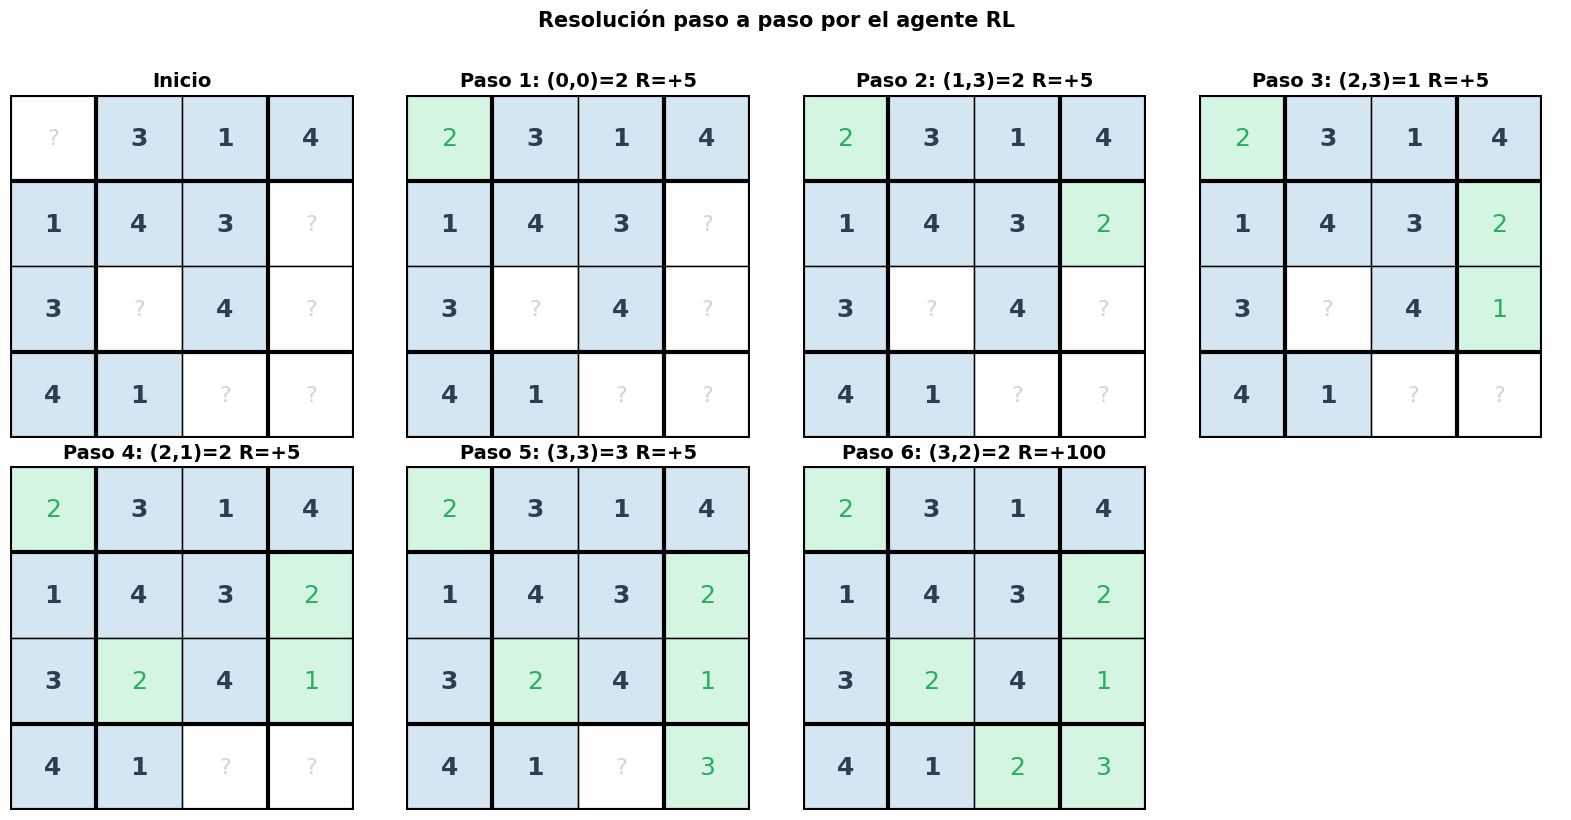

¡Puzzle resuelto en 6 pasos!


In [8]:
# Mostrar el proceso paso a paso con visualización
np.random.seed(77)
env_visual = Sudoku4x4(n_vacias=6)
env_visual.reset()

# Guardar snapshots antes de cada movimiento
tableros = [env_visual.tablero.copy()]
movimientos = []

# Resolver guardando cada paso
for paso in range(15):
    acciones = []
    for (i, j) in env_visual.get_celdas_vacias():
        for num in range(1, 5):
            if env_visual.es_movimiento_valido(i, j, num):
                acciones.append((i, j, num))

    if not acciones:
        break

    estado_hash = agente_medio._estado_hash(env_visual.tablero)
    mejor_q = -np.inf
    mejor_accion = acciones[0]
    for accion in acciones:
        q = agente_medio._get_q(estado_hash, accion)
        if q > mejor_q:
            mejor_q = q
            mejor_accion = accion

    f, c, n = mejor_accion
    _, r, done, info = env_visual.step(f, c, n)
    movimientos.append((f, c, n, r))
    tableros.append(env_visual.tablero.copy())

    if done:
        break

# Visualizar cada paso
n_pasos = len(tableros)
cols = min(n_pasos, 4)
filas = (n_pasos + cols - 1) // cols

fig, axes = plt.subplots(filas, cols, figsize=(4*cols, 4*filas))
if filas == 1:
    axes = [axes] if cols == 1 else axes
    axes = np.array(axes).reshape(1, -1)

for idx in range(filas * cols):
    r_idx, c_idx = idx // cols, idx % cols
    ax = axes[r_idx, c_idx] if filas > 1 else axes[0, c_idx]

    if idx < n_pasos:
        # Recrear entorno para render
        env_snap = Sudoku4x4(n_vacias=6)
        env_snap.reset()
        env_snap.tablero = tableros[idx].copy()
        env_snap.celdas_fijas = env_visual.celdas_fijas
        env_snap.solucion = env_visual.solucion

        if idx == 0:
            titulo = 'Inicio'
        else:
            f, c, n, r = movimientos[idx-1]
            titulo = f'Paso {idx}: ({f},{c})={n} R={r:+.0f}'

        env_snap.render(titulo, ax=ax)
    else:
        ax.axis('off')

plt.suptitle('Resolución paso a paso por el agente RL',
            fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()

if env_visual.esta_resuelto():
    print(f'¡Puzzle resuelto en {len(movimientos)} pasos!')
else:
    print(f'Puzzle no resuelto en {len(movimientos)} pasos')

### Demo 4: Comparación de dificultades

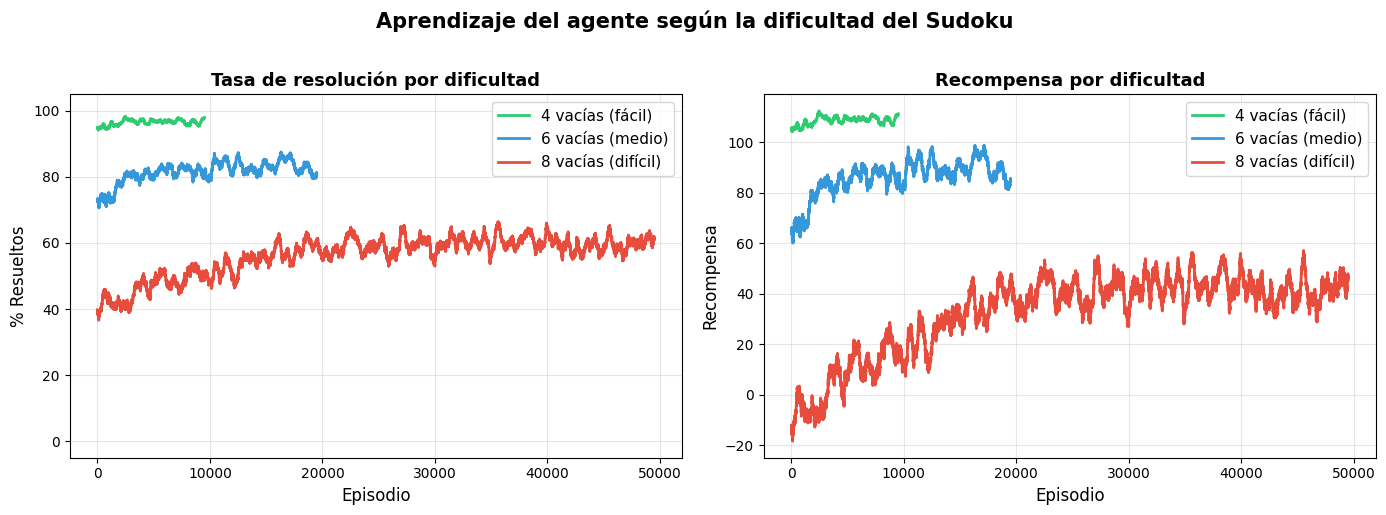

Observaciones:
• A mayor dificultad (más celdas vacías), más episodios necesita para aprender
• El espacio de estados crece exponencialmente con las celdas vacías
• Los puzzles fáciles se aprenden rápido con Q-Learning tabular
• Para Sudoku 9x9, se necesitaría Deep Q-Network (DQN) con redes neuronales


In [9]:
# Curvas de aprendizaje para diferentes dificultades
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

configs = [
    ('4 vacías (fácil)', agente_facil, '#2ecc71'),
    ('6 vacías (medio)', agente_medio, '#3498db'),
    ('8 vacías (difícil)', agente_dificil, '#e74c3c'),
]

# Tasa de resolución
ax = axes[0]
for nombre, agente, color in configs:
    resueltos = [float(x) for x in agente.resueltos_historial]
    v = min(500, len(resueltos) // 5)
    if len(resueltos) >= v:
        tasa = np.convolve(resueltos, np.ones(v)/v, mode='valid') * 100
        ax.plot(tasa, label=nombre, color=color, linewidth=2)
ax.set_xlabel('Episodio', fontsize=12)
ax.set_ylabel('% Resueltos', fontsize=12)
ax.set_title('Tasa de resolución por dificultad', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.set_ylim(-5, 105)
ax.grid(True, alpha=0.3)

# Recompensa
ax = axes[1]
for nombre, agente, color in configs:
    v = min(500, len(agente.recompensas_historial) // 5)
    if len(agente.recompensas_historial) >= v:
        media = np.convolve(agente.recompensas_historial, np.ones(v)/v, mode='valid')
        ax.plot(media, label=nombre, color=color, linewidth=2)
ax.set_xlabel('Episodio', fontsize=12)
ax.set_ylabel('Recompensa', fontsize=12)
ax.set_title('Recompensa por dificultad', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.suptitle('Aprendizaje del agente según la dificultad del Sudoku',
            fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()

print('Observaciones:')
print('• A mayor dificultad (más celdas vacías), más episodios necesita para aprender')
print('• El espacio de estados crece exponencialmente con las celdas vacías')
print('• Los puzzles fáciles se aprenden rápido con Q-Learning tabular')
print('• Para Sudoku 9x9, se necesitaría Deep Q-Network (DQN) con redes neuronales')

### Demo 5: Análisis de la estrategia aprendida

=== Análisis de la estrategia del agente ===

Tablero actual:
[[2 4 1 3]
 [3 1 4 0]
 [4 3 0 1]
 [0 2 0 4]]

Solución:
[[2 4 1 3]
 [3 1 4 2]
 [4 3 2 1]
 [1 2 3 4]]

Acciones válidas y sus Q-values:
Acción (f,c,num)     Q-value      ¿Correcto?
---------------------------------------------
(1,3) = 2              0.0000    ✓ SÍ
(2,2) = 2              0.0000    ✓ SÍ
(3,0) = 1              0.0000    ✓ SÍ
(3,2) = 3              1.5000    ✓ SÍ


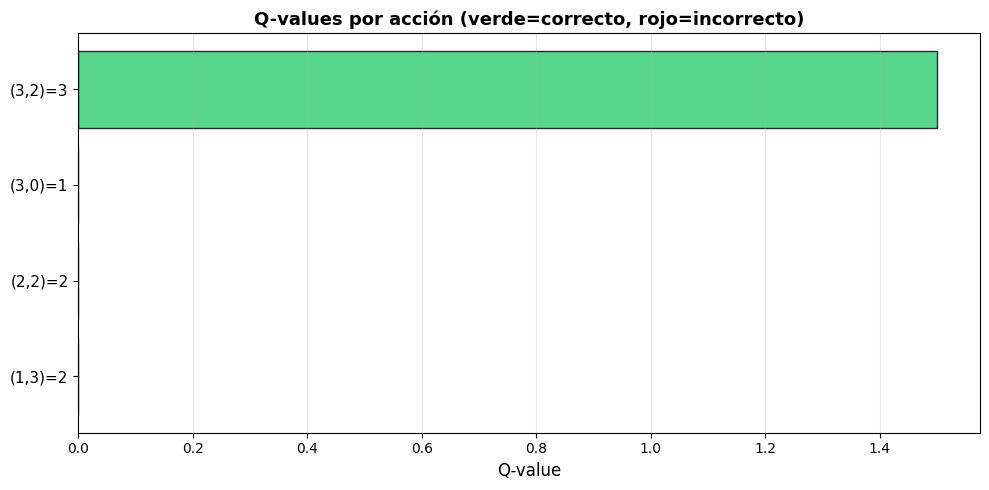


El agente aprende a asignar Q-values más altos a las acciones correctas
y Q-values más bajos (o negativos) a las acciones incorrectas.


In [10]:
# Analizar qué aprende el agente
np.random.seed(42)
env_analisis = Sudoku4x4(n_vacias=4)
env_analisis.reset()

print('=== Análisis de la estrategia del agente ===')
print(f'\nTablero actual:')
print(env_analisis.tablero)
print(f'\nSolución:')
print(env_analisis.solucion)

# Mostrar Q-values para cada acción posible
estado_hash = agente_facil._estado_hash(env_analisis.tablero)
acciones = agente_facil._obtener_acciones_validas(env_analisis)

print(f'\nAcciones válidas y sus Q-values:')
print(f'{"Acción (f,c,num)":<20} {"Q-value":<12} {"¿Correcto?"}')
print('-' * 45)

q_values = []
for accion in acciones:
    f, c, n = accion
    q = agente_facil._get_q(estado_hash, accion)
    correcto = '✓ SÍ' if n == env_analisis.solucion[f, c] else '✗ No'
    print(f'({f},{c}) = {n}          {q:>10.4f}    {correcto}')
    q_values.append((accion, q, n == env_analisis.solucion[f, c]))

# Visualizar Q-values
fig, ax = plt.subplots(figsize=(10, 5))
labels = [f'({a[0]},{a[1]})={a[2]}' for a, _, _ in q_values]
values = [q for _, q, _ in q_values]
correctos = [c for _, _, c in q_values]
colores = ['#2ecc71' if c else '#e74c3c' for c in correctos]

bars = ax.barh(range(len(labels)), values, color=colores, edgecolor='black', alpha=0.8)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=11)
ax.set_xlabel('Q-value', fontsize=12)
ax.set_title('Q-values por acción (verde=correcto, rojo=incorrecto)',
            fontsize=13, fontweight='bold')
ax.axvline(x=0, color='black', linewidth=0.5)
ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout(); plt.show()

print('\nEl agente aprende a asignar Q-values más altos a las acciones correctas')
print('y Q-values más bajos (o negativos) a las acciones incorrectas.')

---

## Resumen

| Aspecto | Detalle |
|---|---|
| **Problema** | Resolver Sudoku 4x4 con RL |
| **Algoritmo** | Q-Learning tabular |
| **Estado** | Configuración del tablero (hash) |
| **Acción** | (fila, columna, número) |
| **Recompensas** | +5/+2 movimiento válido, -10 inválido, +100 resuelto |
| **Exploración** | ε-greedy con decaimiento |
| **Limitación** | Solo funciona con 4x4 (espacio de estados manejable) |
| **Para 9x9** | Se necesitaría Deep Q-Network (DQN) o Policy Gradient |

### Lecciones aprendidas

1. **RL puede resolver puzzles combinatorios** si el espacio de estados es manejable
2. **El diseño de recompensas es crucial**: recompensar movimientos válidos intermedios ayuda mucho
3. **La dificultad escala exponencialmente** con el número de celdas vacías
4. **Q-Learning tabular tiene límites**: para problemas más grandes se necesitan aproximadores de función (redes neuronales)